# Issue #5 · untouched YOLO26n Raw development baseline

Run `01_data_protocol.ipynb` first. This notebook currently implements only the
pretrained development-validation gate; progressive partial fine-tuning belongs to
issue #7. There are **no optimizer steps and no final-test evaluation** here.
Issue #6 supplies `02_adaptive_preprocessing.ipynb` for the frozen policy and nested pilots.
Its quality proxies do not establish detection benefit; no policy fitting happens here.

The release checkpoint stays COCO-80. A small native validator adapter filters and
maps postprocessed predictions by semantic class name to the fixed BDD order:
car, truck, bus, train, motorcycle, bicycle. Native IoU matching, AP, precision/recall
and plots are retained. The checkpoint and its model labels are not rewritten.

YOLO26's inference head is explicit: `nms=False`, the one-to-one end-to-end head.
Keep this inference protocol fixed for the later paired comparisons.

### Review provenance note

The outputs below preserve the original measured inference from commit `b03e535`.
The canonical protocol identity was subsequently corrected to exclude optional legacy
history; split membership, source/label/export identities, checkpoint, mapping and
settings are unchanged. Only cache identity metadata was migrated. **No new inference
was executed for this correction.** See
[`identity_migration.json`](../../docs/issue5/identity_migration.json) for both identities,
checksums and cache verification with `YOLO.val()` forbidden.

For the later Issue #7 paired comparison, label the frozen v2 treatment
**Gamma-or-Skip**. It is not a validated four-operator router. Issue #11 retains
the no-v3 decision; enabling a later route requires group-disjoint calibration
confirmation. Keep natural-distribution and synthetic robustness benchmarks separate.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display
from IPython.utils.capture import capture_output
from ultralytics import YOLO

from vehicle_detection.baseline import (
    COCO_TO_VEHICLE,
    PRETRAINED_SHA256,
    VAL_SETTINGS,
    evaluate_pretrained,
    verify_coco_names,
)
from vehicle_detection.common import file_hash, read_json, write_json
from vehicle_detection.data import CLASSES
from vehicle_detection.protocol import validate_protocol

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
RUN_ROOT = ROOT / "runs/issue5-v1"
REPORT_ROOT = ROOT / "docs/issue5"
OUTPUT = RUN_ROOT / "pretrained_yolo26n_raw_dev"
protocol = validate_protocol(read_json(RUN_ROOT / "protocol.json"))
assert torch.cuda.is_available(), "This recorded protocol requires CUDA device 0"
checkpoint = ROOT / "weights/yolo26n.pt"
pretrained = YOLO(str(checkpoint))  # Native download from Ultralytics assets if absent.
assert file_hash(checkpoint) == PRETRAINED_SHA256
verify_coco_names(pretrained.names)
print("Untouched pretrained checkpoint:", checkpoint, PRETRAINED_SHA256)
display(
    pd.DataFrame(
        [
            {"COCO_ID": source, "BDD_ID": target, "class": CLASSES[target]}
            for source, target in COCO_TO_VEHICLE.items()
        ]
    )
)
display(pd.Series(VAL_SETTINGS, name="frozen native validation settings"))

Untouched pretrained checkpoint: /home/truong51972/projects/vehicle-detection/weights/yolo26n.pt 9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef


,COCO_ID,BDD_ID,class
0,2,0,car
1,7,1,truck
2,5,2,bus
3,6,3,train
4,3,4,motorcycle
5,1,5,bicycle


imgsz              640
batch               32
device               0
conf             0.001
iou                0.7
max_det            300
quantize            32
nms              False
agnostic_nms     False
rect              True
augment          False
seed              2026
deterministic     True
workers              8
plots             True
verbose          False
Name: frozen native validation settings, dtype: object

In [2]:
with capture_output() as validation_log:
    result = evaluate_pretrained(protocol, RUN_ROOT / "datasets/raw", checkpoint, OUTPUT)
(RUN_ROOT / "pretrained_validation.log").write_text(validation_log.stdout + validation_log.stderr)
print(validation_log.stdout[-2000:])
assert result["runtime"]["device"] == "cuda:0"
assert not result["holdout_evaluated"]
display(pd.Series(result["overall"], name="native development Raw metrics"))
per_class = pd.DataFrame(result["classes"])
display(per_class)
print(result["nms_mode"])
print("Native exported-file stage timing, not application end-to-end latency:", result["speed_ms"])
write_json(REPORT_ROOT / "pretrained_baseline.json", read_json(OUTPUT / "native_result.json"))

Ultralytics 8.4.198 🚀 Python-3.11.14 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16284MiB)


YOLO26n summary (fused): 122 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6883.1±2279.5 MB/s, size: 108.8 KB)


val: New cache created: /home/truong51972/projects/vehicle-detection/runs/issue5-v1/datasets/raw/labels/tune.cache


                   all      13975     152795      0.379      0.244      0.223      0.136


Speed: 0.2ms preprocess, 1.1ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/truong51972/projects/vehicle-detection/runs/issue5-v1/pretrained_yolo26n_raw_dev


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 437/437 8.0it/s 54.5s



mAP50        0.223311
mAP50_95     0.136362
precision    0.379020
recall       0.243885
Name: native development Raw metrics, dtype: float64

,class,images,instances,AP50,AP50_95,precision,recall
0,car,13820,142541,0.495790,0.282465,0.675704,0.416259
1,truck,3773,5965,0.229008,0.166944,0.265375,0.334116
2,bus,1759,2276,0.276756,0.212324,0.356215,0.339864
3,train,17,21,0.013523,0.009024,0.028586,0.095238
4,motorcycle,435,562,0.130619,0.062485,0.331865,0.144128
5,bicycle,872,1430,0.194169,0.084930,0.616374,0.133705


nms=False: one-to-one end-to-end head, no external NMS
Native exported-file stage timing, not application end-to-end latency: {'preprocess': 0.2194341503332364, 'inference': 1.0856058819197394, 'loss': 0.00013835793040352932, 'postprocess': 0.5983776849399242}


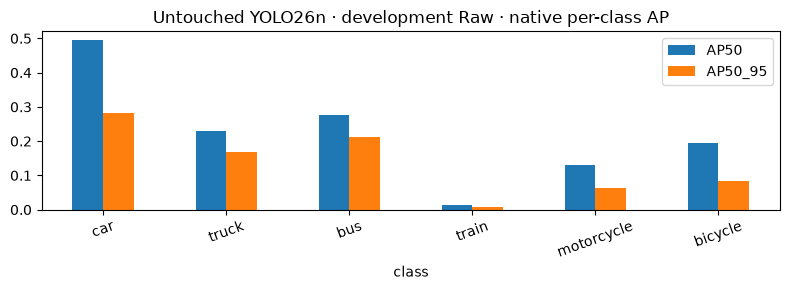

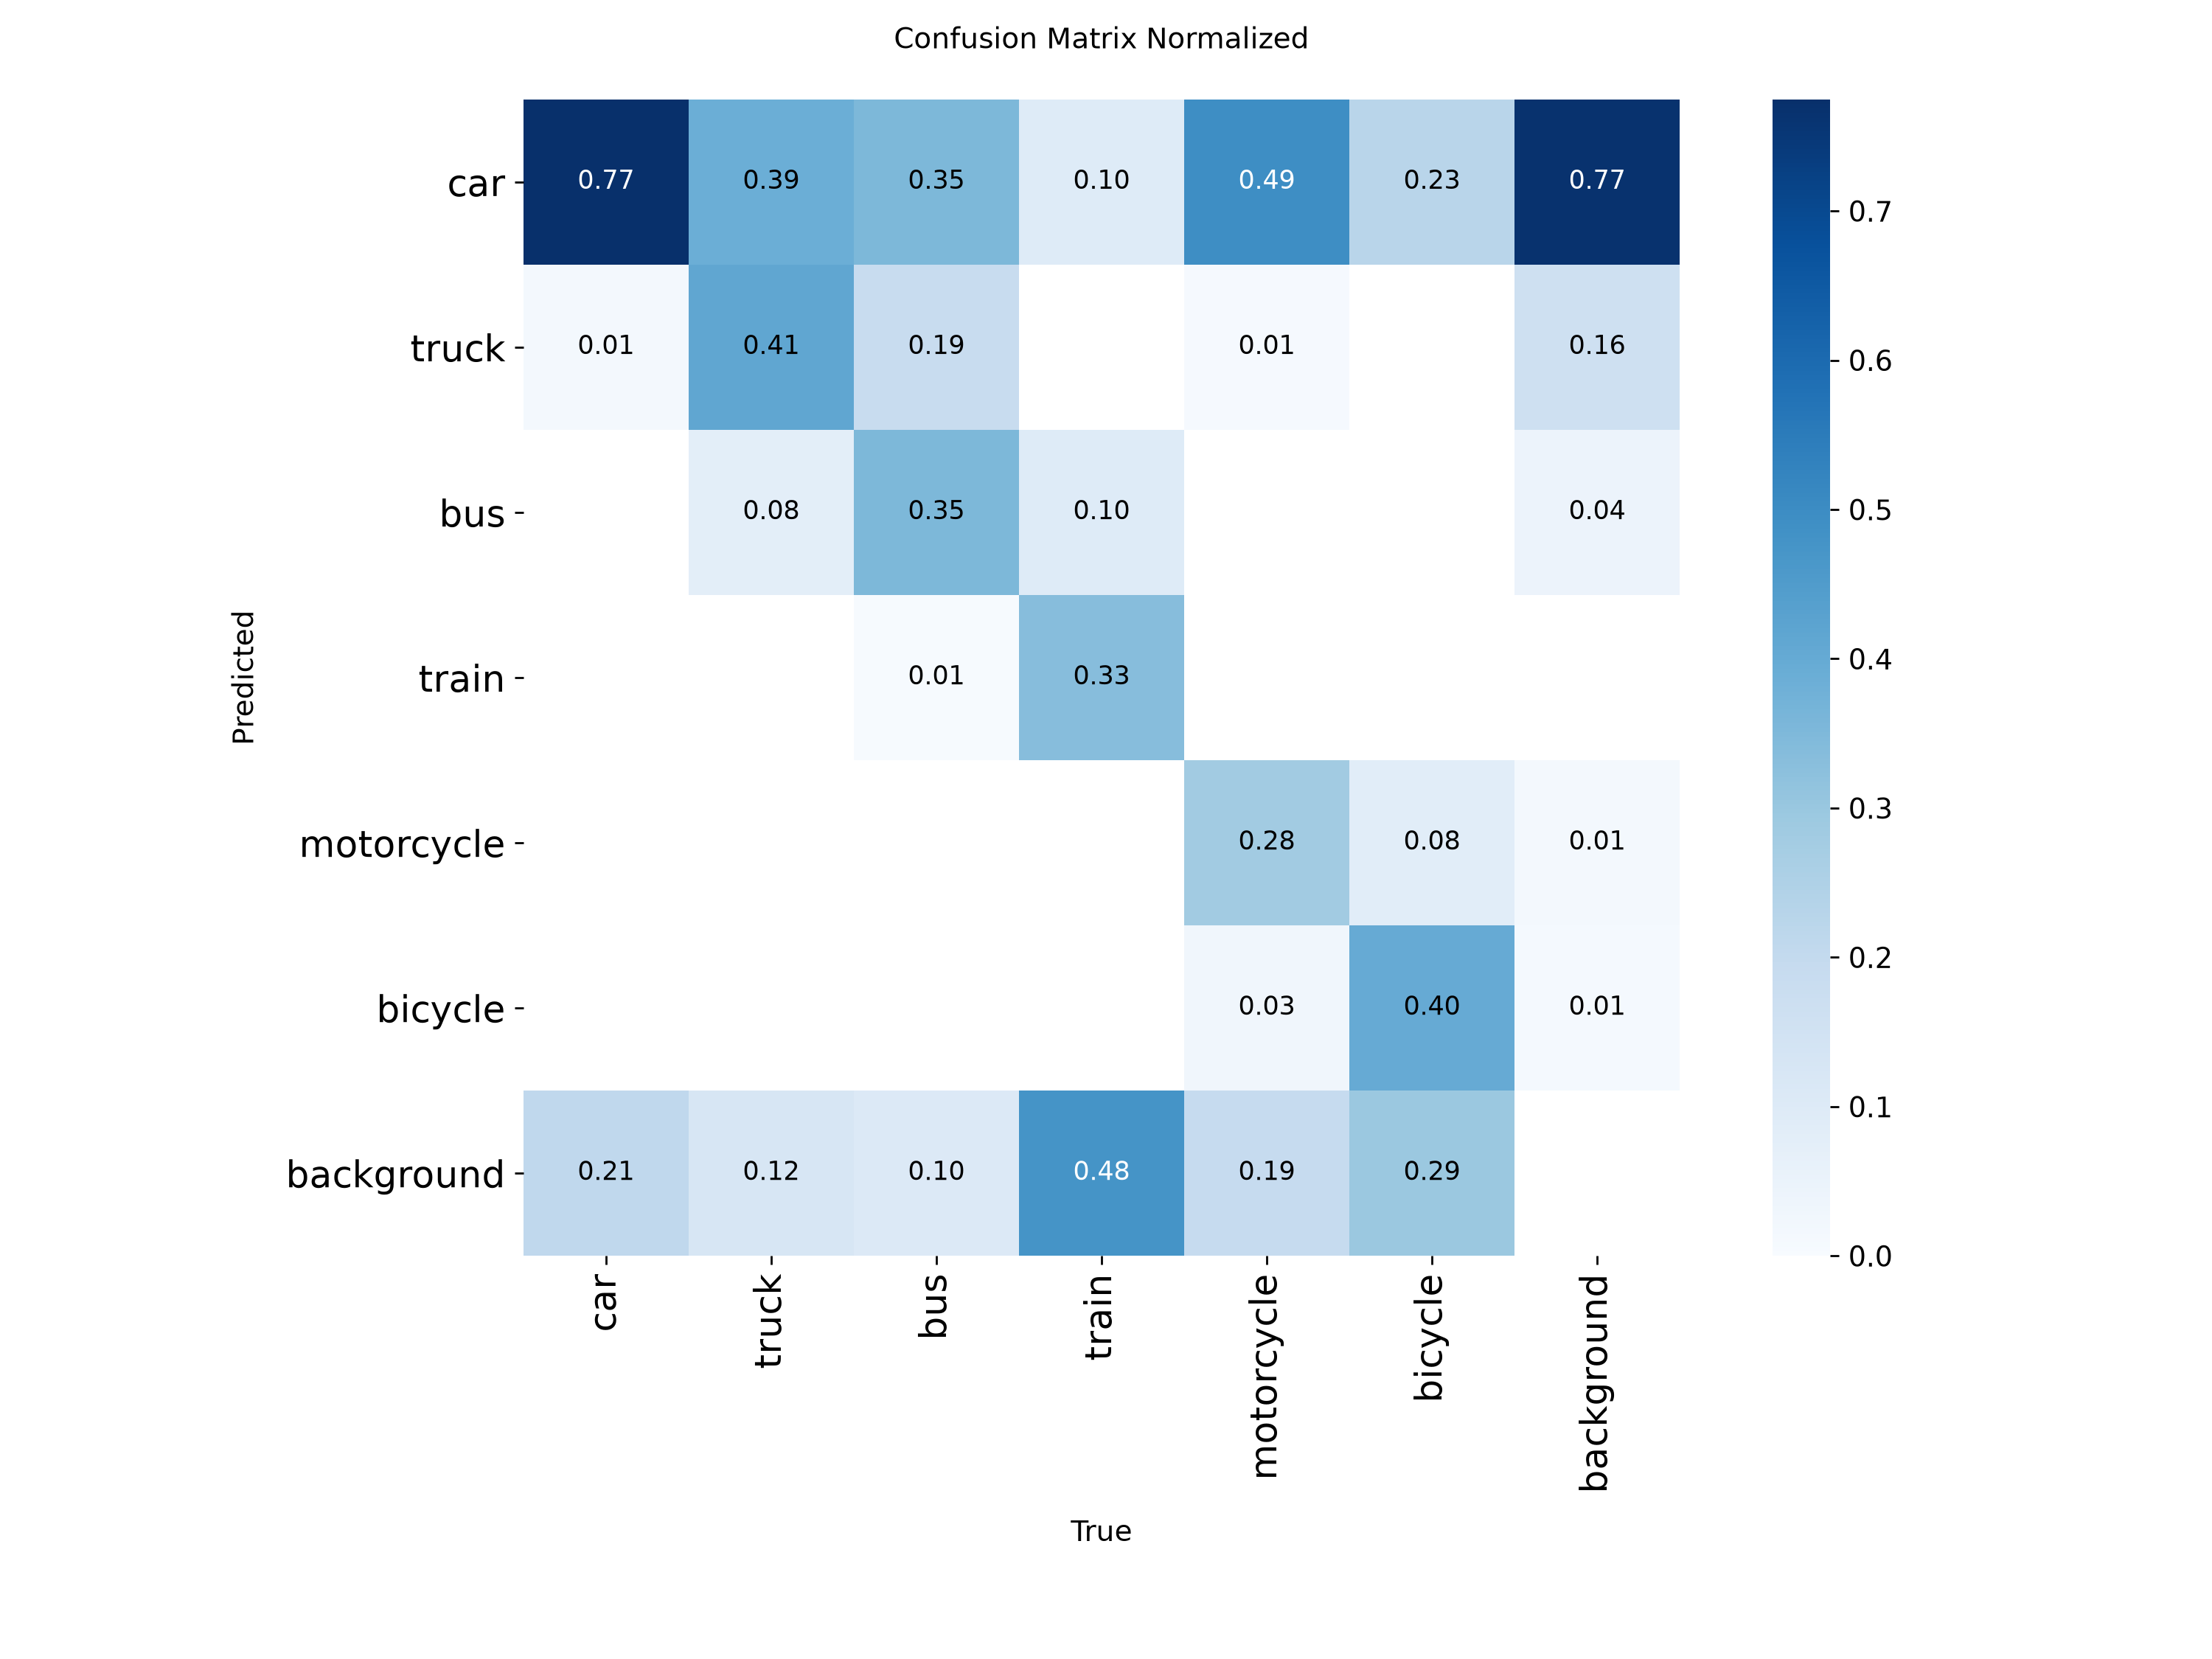

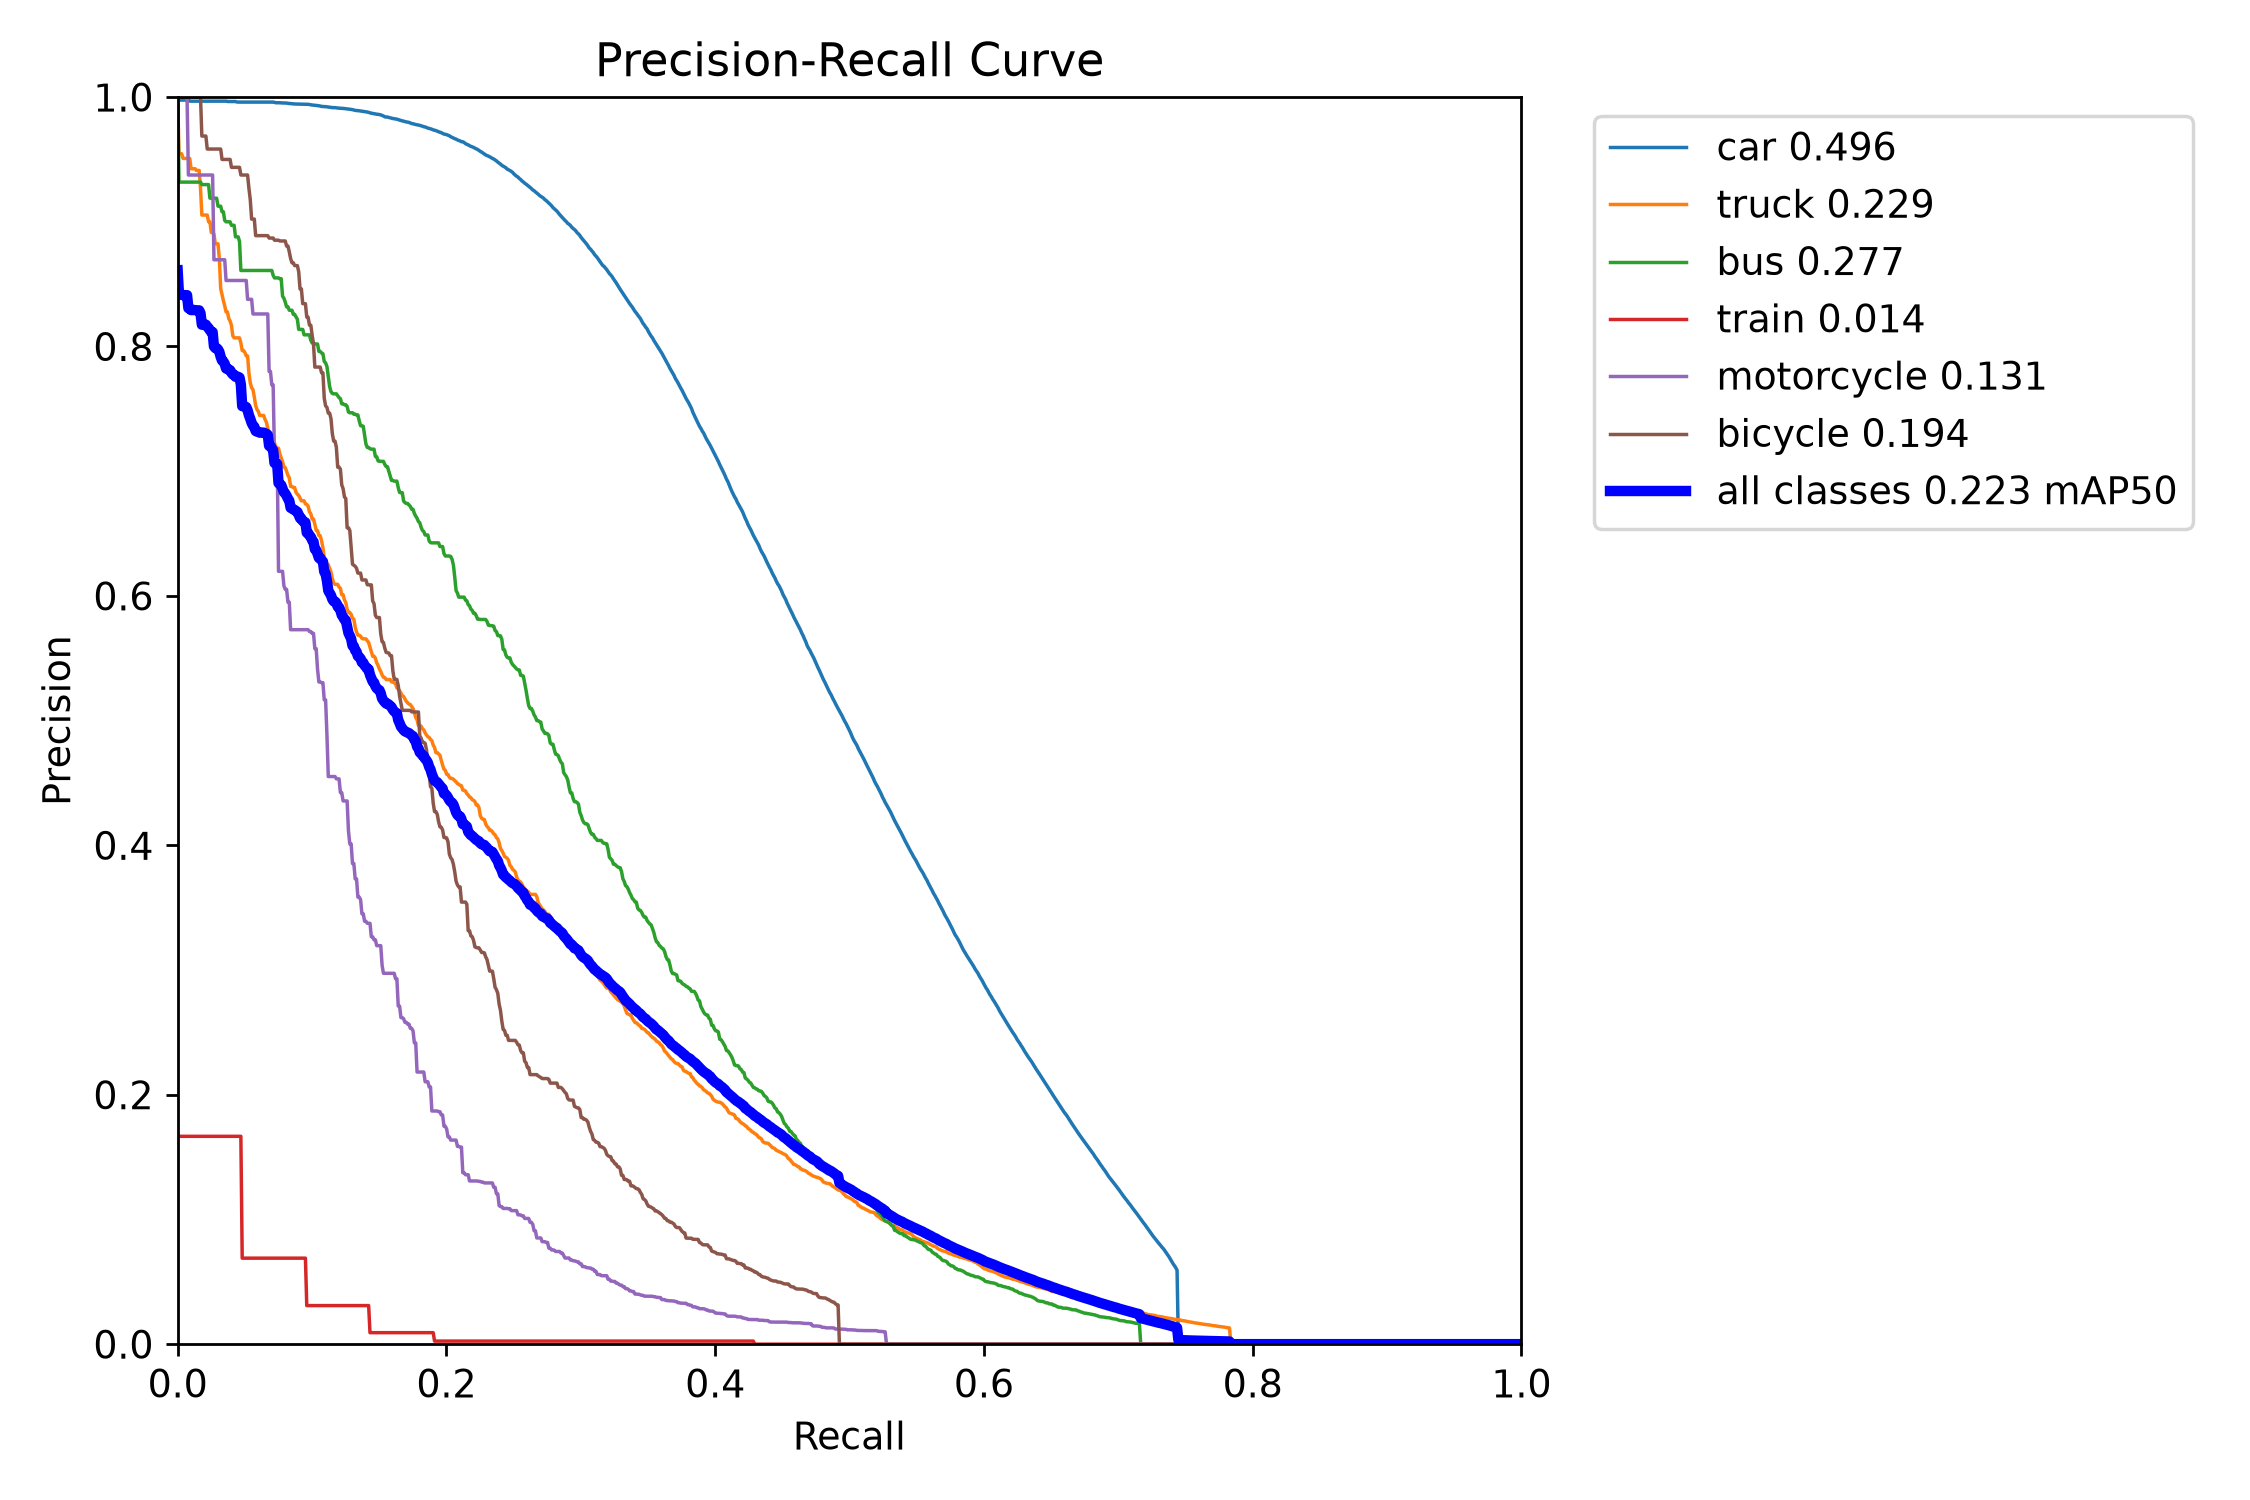

In [3]:
per_class.set_index("class")[["AP50", "AP50_95"]].plot.bar(
    figsize=(8, 3),
    title="Untouched YOLO26n · development Raw · native per-class AP",
    rot=20,
)
plt.tight_layout()
plt.savefig(REPORT_ROOT / "pretrained_class_AP.png")
plt.show()
for pattern in ["confusion_matrix_normalized.png", "*PR_curve.png"]:
    paths = sorted(OUTPUT.glob(pattern))
    assert paths
    display(Image(filename=str(paths[0]), width=800))

In [4]:
# Completed cache reuse must not rerun inference or accept changed experiment identities.
with capture_output():
    reused = evaluate_pretrained(protocol, RUN_ROOT / "datasets/raw", checkpoint, OUTPUT)
assert reused == result
assert file_hash(checkpoint) == PRETRAINED_SHA256
print("PASS: native pretrained development baseline, unchanged checkpoint, verified cache reuse")
print("Final test remains reserved; no final-test metrics or policy selection.")

PASS: native pretrained development baseline, unchanged checkpoint, verified cache reuse
Final test remains reserved; no final-test metrics or policy selection.
